<h3><center>Introduction to Building a Quant Pricing Library</center></h3>
<h1><center>Volatility Surface, Numerical Greeks</center></h1>
<h3><center>Tamas Glatz</h3>
<h3><center>(Based on Gabor Friedmann's Lecutre Notes)</center></h3>
<h4><center>14 October, 2026</center></h4>


### <b> The law of supply and demand:</b>
* Number of people who buy go $ \uparrow $, or sell go $ \downarrow $ $\Longrightarrow $ Price goes $\uparrow$
* Number of people who buy go $ \downarrow $, or sell go $ \uparrow $ $\Longrightarrow $ Price goes $\downarrow $
* This simple dynamic drives the price of many goods... For example
    * Market price of face masks during covid
    * <b> Market price of options<b> (quotes)

## <b>Goal of option pricing:</b>
* Come up with a model that is able to re-price "frequently traded" (liquid) products
* Use the model to understand how to eliminate risks (hedging)
* Use the model to price other, "non-frequently traded" (illiquid) products

# Moneyness

Measures whether the option would make money if it were exercised immediately. We define moneyness as current spot price divided by strike price:
$$ M = \dfrac{S_t}{K} $$

At $M = 1$, the option is called at-the-money (ATM). Otherwise, the option is called either in-the-money (ITM) or out-of-the-money (OTM).

<img src="./img/moneyness.jpg" style="margin-left:auto; margin-right:auto; width: 1000px;" />

## What did we learn?

Black-Scholes model assumptions:
* Underlying asset price follows GBM:

$$ dS_{t}=\mu S_{t}\,dt+\sigma S_{t}\,dW_{t} $$
* Underlying asset price has <b>known and constant</b> volatility ($\sigma$)
* Log returns of the underlying asset are normally distributed

### Under these assumptions we can derive the price of a European Call option $c_0$ (by ruling out arbitrage):

$$
c_0 = S_0 N(d_1) - K e^{-rT} N(d_2)
$$
where
$$
d_1 = \frac{\ln\left(\frac{S_0}{K}\right) + \left(r + \frac{\sigma^2}{2}\right)T}{\sigma\sqrt{T}}; \, d_2 = d_1 - \sigma\sqrt{T}
$$
So essentially $c_0$ is a function of 5 parameters:
$$
c_0 = f_{BS}\left(S_0, K, T, r, {\sigma}\right)
$$
#### Which of these parameters are known to us?

#### Remember, our goal with the model is NOT to determine how much the option we observe should cost, but to know how to hedge it.

$$ \color{red}{\sigma} = f^{-1}_{BS}\left(S_0, K, T, r, c_0\right) $$

<b>Implied volatility</b>: The volatility obtained from market quotes using Black-Scholes formula. It represents what the market is implying the volatility will be in the future based on option prices.

#### Based on BS assumptions, implied volatility should be constant for all options on a given underlying. Is that true?

<img src="./img/implied_vol_smile.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" />

<img src="./img/smile_skew.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" alt="Source: https://analystprep.com/study-notes/frm/part-2/market-risk-measurement-and-management/volatility-smiles/" />

## Why?

Highligting just one concept: Protective Put Option Strategy

There is high demand for put options with low strike as they serve as a protection against huge losses.

<img src="./img/protective_put.jpg" style="margin-left:auto; margin-right:auto; width: 400px;" />


<img src="./img/implied_vol_termskew.jpg" style="margin-left:auto; margin-right:auto; width: 1500px;" />

<b>Conclusion</b>: The volatility in our model should depend on strike and expiry: <b>$ \sigma = \sigma(K,T) $<b>

Using market quotes, we can derive an <b>implied volatility grid</b>. Applying some interpolation technique between grid points we can build an <b>implied volatility surface</b>.

Let's look at some examples!

BlueChip Bank, TipTop Solutions, Money Mall


In [6]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.home() / "QuantCourseBP"))
current = Path(Path().resolve())
sys.path.append(str(current))
sys.path.append(str(current.parents[2]))

from src.utils import *
from src.market_data import *

# Make charts interactive - remove this line if charts throws error
%matplotlib inline

# Initialize market data
MarketData.initialize()

In [8]:
underlying = Stock.BLUECHIP_BANK
volgrid = MarketData.get_volgrid()[underlying]

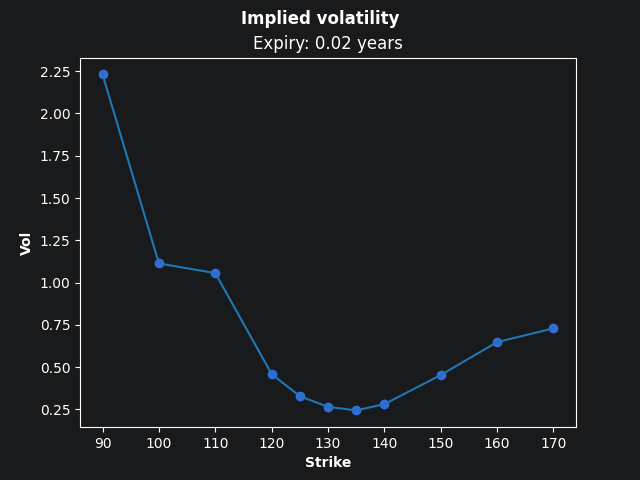

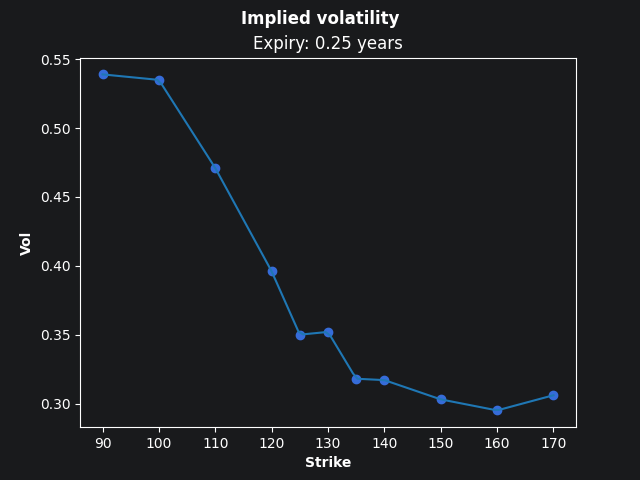

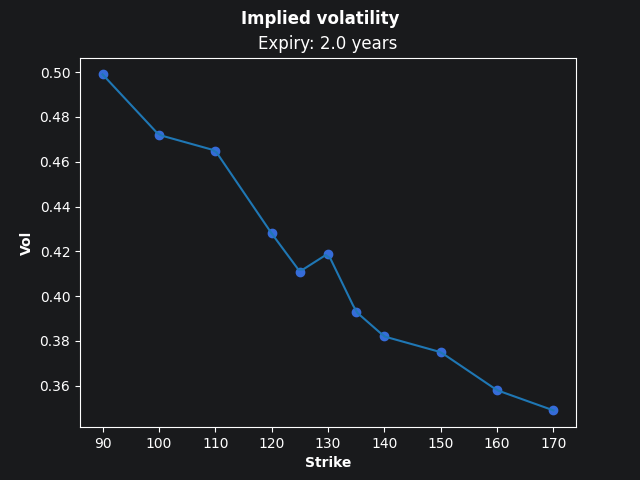

In [9]:
flag = True
plot_vol_slice(volgrid, expiry=0.02, linear_interpolation=flag) # 7D
plot_vol_slice(volgrid, expiry=0.25, linear_interpolation=flag) # 3M
plot_vol_slice(volgrid, expiry=2.00, linear_interpolation=flag) # 2Y

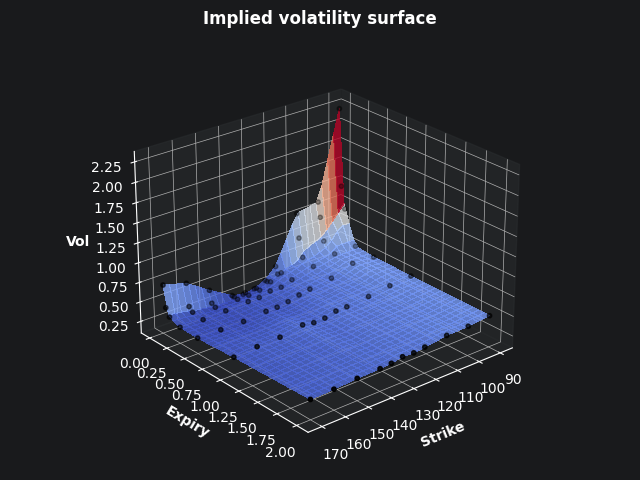

In [10]:
plot_vol_surface(volgrid)

## What changes?

Underlying asset price diffusion:
$$ \; dS_{t}=\mu S_{t}\,dt+\sigma S_{t}\,dW_{t} $$


$$ \; dS_{t}=\mu S_{t}\,dt+\color{red}{\sigma(K,T)} S_{t}\,dW_{t} $$

We can determine $ \sigma(K,T) $ based on the contract we want to price, then use that constant within the Black-Scholes framework. Let's call this extension of BS model as <b>flat volatility model</b>.

Volatility market data is no longer a single number, but a tabular data (grid) for each underlying, hence we outsource them to csv files for maintainability.

<br>
<br>

Let's do coding!

# Tasks

## MarketData - market_data.py

* Understand the new structure of MarketData class
* Understand how VolGrid class works

## MarketModel - model.py

* Implement BSVol and FlatVol models in the pricing library

## Jupyter notebook

* Price a few contracts using both Black-Scholes and FlatVol models

In [7]:
# Add current folder and QuantCourseBP folder to syspath to import modules
import sys
from pathlib import Path
current = Path(Path().resolve())
sys.path.append(str(current))

for p in [str(current.parents[2]),str(current.parents[2]/"src") ]:
    if p in sys.path:
        sys.path.remove(p)

from market_data import MarketData
from pricer import *
from model import *

In [8]:
und = Stock.BLUECHIP_BANK
put_call = PutCallFwd.CALL
ls = LongShort.LONG
strike = 1.0 * MarketData.get_spot()[und] # at-the-money strike i.e. strike = spot price
strike_itm = strike * 1.1
exp = 1

forward = ForwardContract(und, ls, strike, exp)
option = EuropeanContract(und, put_call, ls, strike , exp)
option_itm = EuropeanContract(und, put_call, ls, strike_itm, exp)

print(option)

{'underlying': <Stock.BLUECHIP_BANK: 'BLUECHIP_BANK'>, 'type': <PutCallFwd.CALL: 'CALL'>, 'long_short': <LongShort.LONG: 'LONG'>, 'strike': 100.0, 'expiry': 1}


# Greeks

* Understanding the sensitivities of a porfolio is crutial to eliminate them (hedging)
* So far we had analytical formulas to calculate greeks, usually this is not the case
* In most cases we calculate greeks numerically using finite difference approximation (forward, backward, central)

## Finite difference approximation (central, absolute)
$$ f'(x)\approx\dfrac{f(x+\Delta)-f(x-\Delta)}{2\Delta} $$

$$ f''(x)\approx\dfrac{f'(x+\dfrac{\Delta}{2})-f'(x-\dfrac{\Delta}{2})}{\Delta}\approx\dfrac{f(x+\Delta)-2f(x)+f(x-\Delta)}{\Delta^2} $$

# Tasks

## Pricer - pricer.py

* Implement calc_delta() function using finite difference approximation.
* Compare the results of analytic and numerical formulas for delta and gamma.

# Assignments - Numerical greeks

1. Introduce two class variables in Pricer that store the finite difference method (forward, backward, central) to be used in numerical greek calculation, and whether the bump size is absolute or relative. Create two Enums to store the labels. Implement all combinations for delta and gamma calculation.<br>Compare greeks using the analytic and the finite difference approximation on a set of European options and visualize the numerical error. Compare absolute and relative bumping and suggest optimal bump sizes. **(15 points)**

# Assignment 4 — Numerical Delta and Gamma

We extend the lecture library with forward, backward and central
finite differences, using absolute or relative spot bumps.

All 12 initial tests passed, covering both European calls and puts.

We now compare numerical Greeks with analytic values, visualize
the errors and investigate suitable bump sizes.

In [9]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load our edited Homework 4 library.
homework_folder = (
    Path.home()
    / "QuantCourseBP/homeworks/67241ae/rest_of_homework/Homework_4"
)

if not (homework_folder / "pricer.py").is_file():
    raise FileNotFoundError("Homework_4/pricer.py was not found.")

sys.path.insert(0, str(homework_folder))

from enums import (
    Stock, PutCallFwd, LongShort, GreekMethod,
    FiniteDifferenceMethod, BumpType
)
from market_data import MarketData, VolGrid
from model import FlatVolModel
from contract import EuropeanContract
from pricer import EuropeanAnalyticPricer, Pricer, Params


# Controlled example: constant volatility of 20%.
underlying = Stock.BLUECHIP_BANK

points = np.array([
    [50., 0.25],
    [150., 0.25],
    [50., 2.0],
    [150., 2.0]
])

MarketData.spot = {underlying: 100.}
MarketData.volgrid = {
    underlying: VolGrid(
        underlying, points, np.full(4, 0.20)
    )
}
MarketData.risk_free_rate = 0.05
MarketData.is_initialized = True

model = FlatVolModel(underlying)

contract = EuropeanContract(
    underlying,
    PutCallFwd.CALL,
    LongShort.LONG,
    100.,
    1.
)

pricer = EuropeanAnalyticPricer(contract, model, Params())

print("Imported library from:", homework_folder)
print(f"Call price: {pricer.calc_fair_value():.6f}")
print(f"Analytic delta: {pricer.calc_delta(GreekMethod.ANALYTIC):.6f}")
print(f"Analytic gamma: {pricer.calc_gamma(GreekMethod.ANALYTIC):.6f}")

Imported library from: /Users/marija/QuantCourseBP/homeworks/67241ae/rest_of_homework/Homework_4
Call price: 10.450584
Analytic delta: 0.636831
Analytic gamma: 0.018762


In [10]:
rows = []
h = 0.01

for fd_method in FiniteDifferenceMethod:
    for bump_type in BumpType:
        p = EuropeanAnalyticPricer(contract, model, Params())

        p.fd_method = fd_method
        p.bump_type = bump_type

        # Same effective spot change for both conventions.
        p.absolute_bump_size = h
        p.relative_bump_size = h / model.spot

        delta_ref = p.calc_delta(GreekMethod.ANALYTIC)
        gamma_ref = p.calc_gamma(GreekMethod.ANALYTIC)

        delta_num = p.calc_delta(GreekMethod.BUMP)
        gamma_num = p.calc_gamma(GreekMethod.BUMP)

        rows.append({
            "Method": fd_method.value,
            "Bump type": bump_type.value,
            "Delta": delta_num,
            "Delta abs. error": abs(delta_num - delta_ref),
            "Gamma": gamma_num,
            "Gamma abs. error": abs(gamma_num - gamma_ref)
        })

comparison = pd.DataFrame(rows)

print(f"Effective spot bump: h = {h}")
print(f"Analytic delta: {delta_ref:.10f}")
print(f"Analytic gamma: {gamma_ref:.10f}")

display(comparison)

Effective spot bump: h = 0.01
Analytic delta: 0.6368306512
Analytic gamma: 0.0187620173


,Method,Bump type,Delta,Delta abs. error,Gamma,Gamma abs. error
0,FORWARD,ABSOLUTE,0.636924,9.380149e-05,0.018757,5.161224e-06
1,FORWARD,RELATIVE,0.636924,9.380149e-05,0.018757,5.161224e-06
2,BACKWARD,ABSOLUTE,0.636737,9.381868e-05,0.018767,5.158059e-06
3,BACKWARD,RELATIVE,0.636737,9.381868e-05,0.018767,5.158059e-06
4,CENTRAL,ABSOLUTE,0.636831,8.599305e-09,0.018762,2.681133e-10
5,CENTRAL,RELATIVE,0.636831,8.599305e-09,0.018762,2.681133e-10


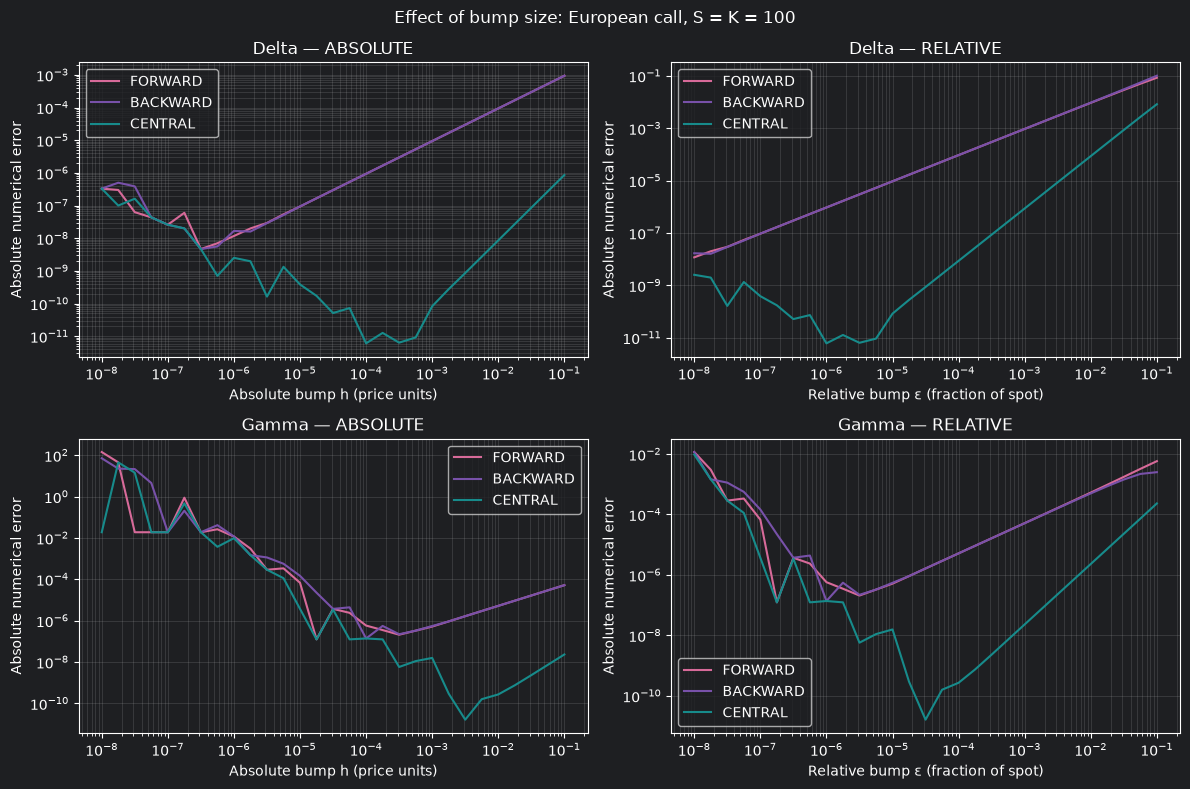

In [11]:
bump_parameters = np.logspace(-8, -1, 29)
sweep_rows = []

delta_ref = pricer.calc_delta(GreekMethod.ANALYTIC)
gamma_ref = pricer.calc_gamma(GreekMethod.ANALYTIC)

for bump_type in BumpType:
    for fd_method in FiniteDifferenceMethod:
        for bump in bump_parameters:
            p = EuropeanAnalyticPricer(contract, model, Params())

            p.fd_method = fd_method
            p.bump_type = bump_type
            p.absolute_bump_size = bump
            p.relative_bump_size = bump

            sweep_rows.append({
                "method": fd_method.value,
                "bump_type": bump_type.value,
                "parameter": bump,
                "effective_h": (
                    bump if bump_type == BumpType.ABSOLUTE
                    else bump * model.spot
                ),
                "delta_error": abs(
                    p.calc_delta(GreekMethod.BUMP) - delta_ref
                ),
                "gamma_error": abs(
                    p.calc_gamma(GreekMethod.BUMP) - gamma_ref
                )
            })

sweep = pd.DataFrame(sweep_rows)

colors = {
    "FORWARD": "#D76A99",
    "BACKWARD": "#7851A9",
    "CENTRAL": "#178B8B"
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for column, bump_type in enumerate(BumpType):
    for row, greek in enumerate(["delta", "gamma"]):
        ax = axes[row, column]

        for fd_method in FiniteDifferenceMethod:
            selected = sweep[
                (sweep["bump_type"] == bump_type.value)
                & (sweep["method"] == fd_method.value)
            ]

            ax.loglog(
                selected["parameter"],
                selected[f"{greek}_error"].clip(lower=1e-18),
                color=colors[fd_method.value],
                label=fd_method.value
            )

        ax.set_title(f"{greek.title()} — {bump_type.value}")
        ax.set_xlabel(
            "Absolute bump h (price units)"
            if bump_type == BumpType.ABSOLUTE
            else "Relative bump ε (fraction of spot)"
        )
        ax.set_ylabel("Absolute numerical error")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend()

fig.suptitle("Effect of bump size: European call, S = K = 100")
fig.tight_layout()
plt.show()

## Comparison across multiple European options

We test 36 contracts: three spot levels, three strike-to-spot
ratios, two expiries, and both calls and puts.

For each contract, absolute and relative bumping use the same
effective spot change h = 0.01, making the comparison fair.
We report mean and maximum absolute errors.

In [13]:
from copy import deepcopy
from itertools import product

results = []
h = 0.01

for spot, ratio, expiry, option_type in product(
    [50., 100., 200.],
    [0.8, 1.0, 1.2],
    [0.5, 2.0],
    [PutCallFwd.CALL, PutCallFwd.PUT]
):
    # Use a separate model for each contract.
    local_model = deepcopy(model)
    local_model.spot = spot

    local_contract = EuropeanContract(
        underlying,
        option_type,
        LongShort.LONG,
        ratio * spot,
        expiry
    )

    for fd_method in FiniteDifferenceMethod:
        for bump_type in BumpType:
            p = EuropeanAnalyticPricer(
                local_contract, local_model, Params()
            )

            p.fd_method = fd_method
            p.bump_type = bump_type
            p.absolute_bump_size = h
            p.relative_bump_size = h / spot

            results.append({
                "spot": spot,
                "strike": ratio * spot,
                "expiry": expiry,
                "option": option_type.value,
                "method": fd_method.value,
                "bump_type": bump_type.value,
                "delta_error": abs(
                    p.calc_delta(GreekMethod.BUMP)
                    - p.calc_delta(GreekMethod.ANALYTIC)
                ),
                "gamma_error": abs(
                    p.calc_gamma(GreekMethod.BUMP)
                    - p.calc_gamma(GreekMethod.ANALYTIC)
                )
            })

option_errors = pd.DataFrame(results)

summary = option_errors.groupby(
    ["method", "bump_type"]
).agg(
    mean_delta_error=("delta_error", "mean"),
    max_delta_error=("delta_error", "max"),
    mean_gamma_error=("gamma_error", "mean"),
    max_gamma_error=("gamma_error", "max")
)

print("Errors across 36 European options; effective h = 0.01")
display(summary)

Errors across 36 European options; effective h = 0.01


mean_delta_error  max_delta_error  mean_gamma_error  \
method   bump_type                                                        
BACKWARD ABSOLUTE       7.943581e-05     2.736367e-04      9.593464e-06   
         RELATIVE       7.943581e-05     2.736367e-04      9.593464e-06   
CENTRAL  ABSOLUTE       1.598926e-08     6.958773e-08      1.112913e-09   
         RELATIVE       1.598926e-08     6.958773e-08      1.112913e-09   
FORWARD  ABSOLUTE       7.942413e-05     2.735364e-04      9.593556e-06   
         RELATIVE       7.942413e-05     2.735364e-04      9.593556e-06   

                    max_gamma_error  
method   bump_type                   
BACKWARD ABSOLUTE      4.176470e-05  
         RELATIVE      4.176470e-05  
CENTRAL  ABSOLUTE      7.265160e-09  
         RELATIVE      7.265160e-09  
FORWARD  ABSOLUTE      4.174028e-05  
         RELATIVE      4.174028e-05

In [14]:
# Build the test pricers and calculate analytic reference values once.
test_cases = []

contracts_to_test = option_errors[
    ["spot", "strike", "expiry", "option"]
].drop_duplicates()

for case in contracts_to_test.itertuples(index=False):
    local_model = deepcopy(model)
    local_model.spot = case.spot

    local_contract = EuropeanContract(
        underlying,
        PutCallFwd(case.option),
        LongShort.LONG,
        case.strike,
        case.expiry
    )

    p = EuropeanAnalyticPricer(
        local_contract, local_model, Params()
    )

    test_cases.append((
        p,
        p.calc_delta(GreekMethod.ANALYTIC),
        p.calc_gamma(GreekMethod.ANALYTIC)
    ))


# Absolute parameters are price units; relative parameters are fractions.
bump_grids = {
    BumpType.ABSOLUTE: np.logspace(-7, 1, 33),
    BumpType.RELATIVE: np.logspace(-9, -1, 33)
}

optimal_rows = []

for bump_type, bump_grid in bump_grids.items():
    for fd_method in FiniteDifferenceMethod:
        for bump in bump_grid:
            delta_errors = []
            gamma_errors = []

            for p, delta_ref, gamma_ref in test_cases:
                p.fd_method = fd_method
                p.bump_type = bump_type
                p.absolute_bump_size = bump
                p.relative_bump_size = bump

                delta_errors.append(abs(
                    p.calc_delta(GreekMethod.BUMP) - delta_ref
                ))
                gamma_errors.append(abs(
                    p.calc_gamma(GreekMethod.BUMP) - gamma_ref
                ))

            optimal_rows.append({
                "method": fd_method.value,
                "bump_type": bump_type.value,
                "bump": bump,
                "mean_delta_error": np.mean(delta_errors),
                "mean_gamma_error": np.mean(gamma_errors)
            })

optimal_sweep = pd.DataFrame(optimal_rows)

# Find the best tested parameter for each method and bump convention.
best_tables = []

for greek in ["delta", "gamma"]:
    error_column = f"mean_{greek}_error"

    best_indices = optimal_sweep.groupby(
        ["method", "bump_type"]
    )[error_column].idxmin()

    best = optimal_sweep.loc[
        best_indices, ["method", "bump_type", "bump", error_column]
    ].copy()

    best["greek"] = greek
    best = best.rename(columns={error_column: "mean_absolute_error"})
    best_tables.append(best)

best_bumps = pd.concat(best_tables, ignore_index=True)

display(best_bumps[
    ["greek", "method", "bump_type", "bump", "mean_absolute_error"]
])

,greek,method,bump_type,bump,mean_absolute_error
0,delta,BACKWARD,ABSOLUTE,1.000000e-06,1.228683e-08
1,delta,BACKWARD,RELATIVE,1.000000e-08,1.022996e-08
2,delta,CENTRAL,ABSOLUTE,1.778279e-04,2.248001e-11
3,delta,CENTRAL,RELATIVE,3.162278e-06,1.466097e-11
4,delta,FORWARD,ABSOLUTE,1.000000e-06,1.372794e-08
5,delta,FORWARD,RELATIVE,1.000000e-08,1.083739e-08
6,gamma,BACKWARD,ABSOLUTE,3.162278e-04,3.993050e-07
7,gamma,BACKWARD,RELATIVE,3.162278e-06,3.600988e-07
8,gamma,CENTRAL,ABSOLUTE,5.623413e-03,7.500742e-10
9,gamma,CENTRAL,RELATIVE,1.000000e-04,3.968684e-10


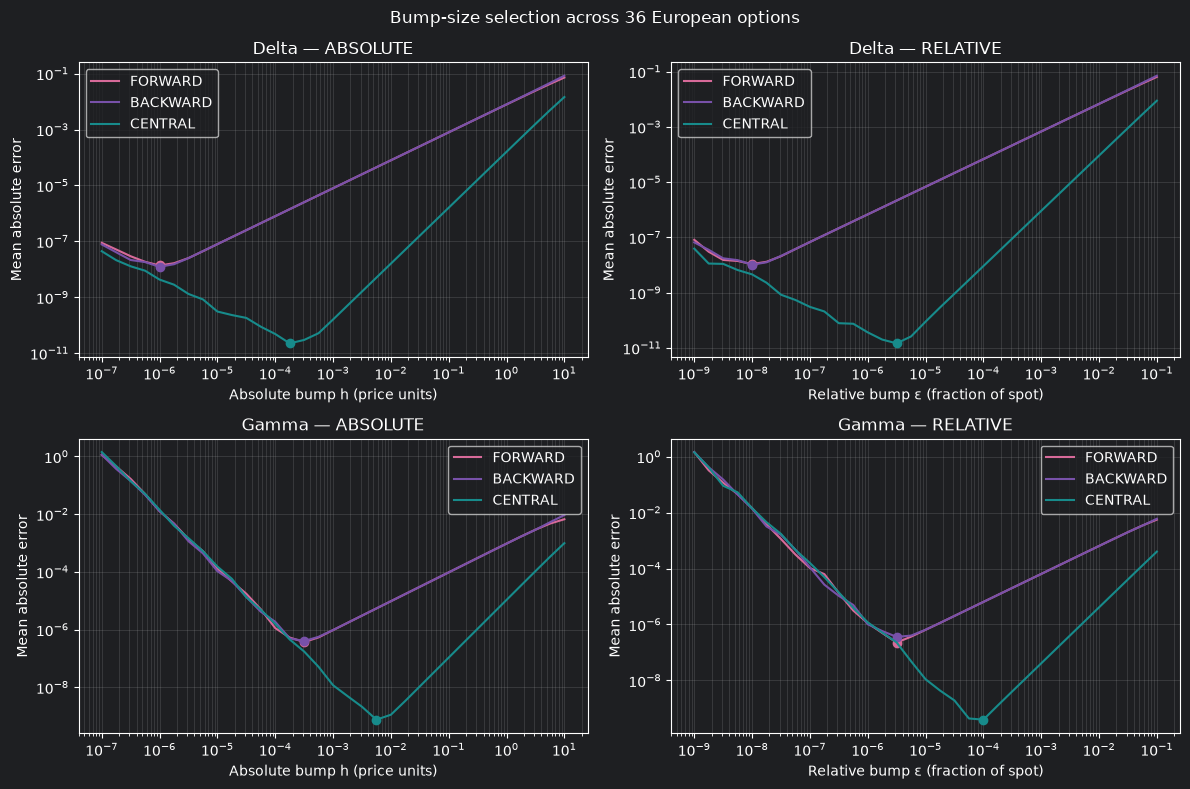

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

colors = {
    "FORWARD": "#D76A99",
    "BACKWARD": "#7851A9",
    "CENTRAL": "#178B8B"
}

for column, bump_type in enumerate(BumpType):
    for row, greek in enumerate(["delta", "gamma"]):
        ax = axes[row, column]
        error_column = f"mean_{greek}_error"

        for fd_method in FiniteDifferenceMethod:
            selected = optimal_sweep[
                (optimal_sweep["bump_type"] == bump_type.value)
                & (optimal_sweep["method"] == fd_method.value)
            ].sort_values("bump")

            ax.loglog(
                selected["bump"],
                selected[error_column].clip(lower=1e-18),
                color=colors[fd_method.value],
                label=fd_method.value
            )

            # Mark the best tested bump.
            best = selected.loc[selected[error_column].idxmin()]

            ax.plot(
                best["bump"],
                max(best[error_column], 1e-18),
                "o",
                color=colors[fd_method.value]
            )

        ax.set_title(f"{greek.title()} — {bump_type.value}")
        ax.set_xlabel(
            "Absolute bump h (price units)"
            if bump_type == BumpType.ABSOLUTE
            else "Relative bump ε (fraction of spot)"
        )
        ax.set_ylabel("Mean absolute error")
        ax.grid(True, which="both", alpha=0.25)
        ax.legend()

fig.suptitle("Bump-size selection across 36 European options")
fig.tight_layout()
plt.show()

In [17]:
print(best_bumps[
    ["greek", "method", "bump_type", "bump", "mean_absolute_error"]
].to_string(
    index=False,
    float_format=lambda x: f"{x:.6e}"
))

greek   method bump_type         bump  mean_absolute_error
delta BACKWARD  ABSOLUTE 1.000000e-06         1.228683e-08
delta BACKWARD  RELATIVE 1.000000e-08         1.022996e-08
delta  CENTRAL  ABSOLUTE 1.778279e-04         2.248001e-11
delta  CENTRAL  RELATIVE 3.162278e-06         1.466097e-11
delta  FORWARD  ABSOLUTE 1.000000e-06         1.372794e-08
delta  FORWARD  RELATIVE 1.000000e-08         1.083739e-08
gamma BACKWARD  ABSOLUTE 3.162278e-04         3.993050e-07
gamma BACKWARD  RELATIVE 3.162278e-06         3.600988e-07
gamma  CENTRAL  ABSOLUTE 5.623413e-03         7.500742e-10
gamma  CENTRAL  RELATIVE 1.000000e-04         3.968684e-10
gamma  FORWARD  ABSOLUTE 3.162278e-04         3.688133e-07
gamma  FORWARD  RELATIVE 3.162278e-06         2.257829e-07


## Results and conclusions

We compared numerical delta and gamma with analytic values across
36 European call and put contracts, using spot levels 50, 100 and
200, strike-to-spot ratios 0.8, 1.0 and 1.2, and expiries 0.5 and
2 years. Volatility was fixed at 20% and the interest rate at 5%.

### Best tested central-difference bumps


Central differences achieved substantially smaller minimum mean
errors than forward and backward differences in this experiment.

The error curves show a balance between two effects:
- Large bumps increase finite-difference approximation error.
- Very small bumps increase floating-point cancellation error,
  especially for gamma, whose formula divides by h².

Absolute and relative bumping produce equivalent results when
their effective spot changes are equal. However, one fixed
relative parameter scales the bump with spot, while one fixed
absolute parameter applies the same price change to every contract.

### Recommendations

For this test set, use central differences with:
- Relative bump ε ≈ 3.16e-6 for delta.
- Relative bump ε = 1e-4 for gamma.

Relative bumping achieved slightly lower minimum mean errors
in these experiments and scales naturally with spot.

These recommendations minimize mean absolute error within the
tested parameter grids and contracts. They are not universally
optimal and may change with volatility, maturity and moneyness.

All 12 initial unit tests passed.